Original Dataset:
   X   Y
0  1   5
1  2   7
2  3   9
3  4  11
4  5  13
5  6  15
6  7  17
7  8  19
8  9  21

 OLS
Intercept: 2.9999999999999982
Coefficient: 2.0000000000000004
MSE: 7.888609052210118e-31
R2 Score: 1.0

 Ridge
Intercept: 3.163934426229508
Coefficient: 1.9672131147540985
MSE: 0.007166532294186063
R2 Score: 0.999731255038968

 Lasso
Intercept: 3.75
Coefficient: 1.85
MSE: 0.14999999999999944
R2 Score: 0.994375

Model Comparison:
Model  Intercept  Coefficient    MSE  R2 Score
  OLS     3.0000       2.0000 0.0000    1.0000
Ridge     3.1639       1.9672 0.0072    0.9997
Lasso     3.7500       1.8500 0.1500    0.9944


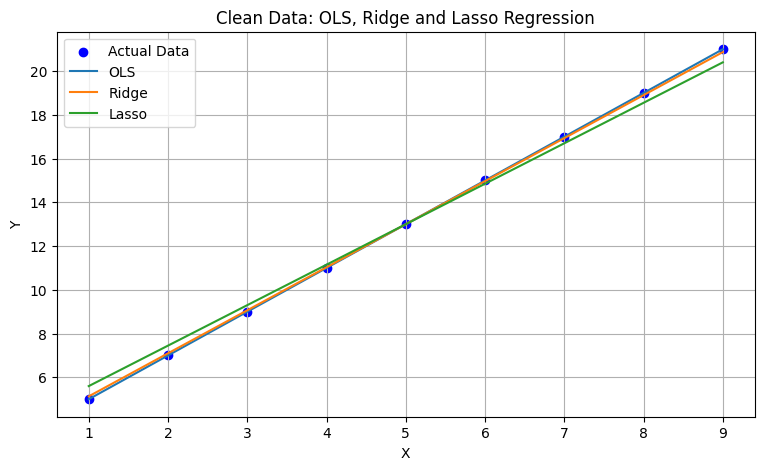

In [1]:

# Clean Data using OLS, Ridge and Lasso Regression

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# 2. Create dataset
data = {
    'X': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Y': [5, 7, 9, 11, 13, 15, 17, 19, 21]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 3. Prepare data
X = df[['X']]
y = df['Y']

# 4. Define regression models
models = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0, max_iter=10000)
}

results = []

# 5. Train and evaluate models
for name, model in models.items():

    model.fit(X, y)

    predictions = model.predict(X)

    mse = mean_squared_error(y, predictions)
    r2 = r2_score(y, predictions)

    results.append({
        'Model': name,
        'Intercept': model.intercept_,
        'Coefficient': model.coef_[0],
        'MSE': mse,
        'R2 Score': r2
    })

    print("\n", name)
    print("Intercept:", model.intercept_)
    print("Coefficient:", model.coef_[0])
    print("MSE:", mse)
    print("R2 Score:", r2)

# 6. Display comparison
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))

# 7. Visualize regression models
plt.figure(figsize=(9, 5))

plt.scatter(X, y, color='blue', label='Actual Data')

for name, model in models.items():
    plt.plot(
        X,
        model.predict(X),
        label=name
    )

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Clean Data: OLS, Ridge and Lasso Regression')
plt.legend()
plt.grid(True)
plt.show()
